# Phase 1: Data Inspection and Preparation

In [2]:
import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current working directory: /Users/siri/Projects/cyclone-sensor-rag-system/Task1/notebooks
Files in current directory: ['task1_analysis.ipynb']


Step 1 — Load and inspect

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load original dataset
df = pd.read_excel(
    "../data/raw/data.xlsx",
    sheet_name="internship-data-1"
)

print(df.shape)
print(df.dtypes)
print(df.head())

/Users/siri/Projects/cyclone-sensor-rag-system/Task1/env1/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


(377719, 7)
time                        datetime64[us]
Cyclone_Inlet_Gas_Temp              object
Cyclone_Material_Temp               object
Cyclone_Outlet_Gas_draft            object
Cyclone_cone_draft                  object
Cyclone_Gas_Outlet_Temp             object
Cyclone_Inlet_Draft                 object
dtype: object
                 time Cyclone_Inlet_Gas_Temp Cyclone_Material_Temp  \
0 2017-01-01 00:00:00                 867.63                910.42   
1 2017-01-01 00:05:00                 879.23                918.14   
2 2017-01-01 00:10:00                 875.67                924.18   
3 2017-01-01 00:15:00                 875.28                923.15   
4 2017-01-01 00:20:00                 891.66                934.26   

  Cyclone_Outlet_Gas_draft Cyclone_cone_draft Cyclone_Gas_Outlet_Temp  \
0                  -189.54            -186.04                  852.13   
1                  -184.33             -182.1                  862.53   
2                  -181.26       

Step 2 — Validate the 6 sensor variables are present

In [7]:
sensor_cols = [
    "Cyclone_Inlet_Gas_Temp", "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft", "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp", "Cyclone_Inlet_Draft",
]
assert all(c in df.columns for c in sensor_cols)

Step 3 — Capture malformed values BEFORE coercing (for the quality report)

In [8]:
quality_rows = []
for c in sensor_cols:
    is_str = df[c].apply(lambda x: isinstance(x, str))
    vc = df.loc[is_str, c].value_counts()
    for val, cnt in vc.items():
        quality_rows.append({"column": c, "issue_type": "non_numeric_value", "value": val, "count": cnt})
    print(c, "non-numeric count:", is_str.sum())

Cyclone_Inlet_Gas_Temp non-numeric count: 1320
Cyclone_Material_Temp non-numeric count: 1591
Cyclone_Outlet_Gas_draft non-numeric count: 1321
Cyclone_cone_draft non-numeric count: 1320
Cyclone_Gas_Outlet_Temp non-numeric count: 1321
Cyclone_Inlet_Draft non-numeric count: 1322


Step 4 — Convert to numeric (fault-code strings become NaN)

In [9]:
for c in sensor_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

Step 5 — Duplicate timestamps (confirm none, but keep the check — don’t assume)

In [10]:
dupe_count = df["time"].duplicated().sum()
quality_rows.append({"column": "time", "issue_type": "duplicate_timestamps", "value": None, "count": dupe_count})
df = df.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)

Step 6 — Reindex onto a strict 5-minute grid (this materializes the gaps)

In [11]:
df = df.set_index("time")
full_index = pd.date_range(df.index.min(), df.index.max(), freq="5min")
df = df.reindex(full_index)
df.index.name = "time"

Step 7 — Identify and classify gaps

In [13]:
is_missing = df[sensor_cols].isna().all(axis=1)
gap_id = (is_missing != is_missing.shift()).cumsum()
gap_events = (
    df[is_missing].groupby(gap_id[is_missing])
    .apply(lambda g: pd.Series({"start": g.index.min(), "end": g.index.max(), "n_slots": len(g)}))
)
print(gap_events)   # should show 3 events of ~287 slots each, on the three Dec-31 dates

                  start                 end  n_slots
2   2017-01-09 13:55:00 2017-01-09 15:35:00       21
4   2017-01-10 23:05:00 2017-01-11 01:30:00       30
6   2017-01-20 10:25:00 2017-01-20 10:25:00        1
8   2017-02-23 09:20:00 2017-02-23 09:25:00        2
10  2017-02-23 09:35:00 2017-02-23 09:55:00        5
..                  ...                 ...      ...
156 2019-12-11 09:20:00 2019-12-11 09:20:00        1
158 2019-12-26 10:05:00 2019-12-26 10:05:00        1
160 2019-12-27 10:05:00 2019-12-27 11:00:00       12
162 2019-12-31 00:05:00 2019-12-31 23:55:00      287
164 2020-01-29 19:25:00 2020-01-29 21:15:00       23

[82 rows x 3 columns]


Step 8 — Flag the 3 structural outage days, handle missing values differently for each case

In [14]:
df["is_data_gap"] = False
for _, row in gap_events.iterrows():
    df.loc[row["start"]:row["end"], "is_data_gap"] = True

# Short, scattered NaNs (fault codes) -> time-based interpolation, capped so it can't bridge the big gaps
df[sensor_cols] = df[sensor_cols].interpolate(method="time", limit=6, limit_direction="both")

remaining_na = df[sensor_cols].isna().sum()
print(remaining_na)   # should now be close to 861 per column — the 3 outage days, left as NaN on purpose

Cyclone_Inlet_Gas_Temp      1703
Cyclone_Material_Temp       1703
Cyclone_Outlet_Gas_draft    1703
Cyclone_cone_draft          1703
Cyclone_Gas_Outlet_Temp     1703
Cyclone_Inlet_Draft         1703
dtype: int64


Step 9 — Outlier investigation (document, don’t blindly delete)

In [15]:
outlier_summary = []
for c in sensor_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    outlier_summary.append({"column": c, "q1": q1, "q3": q3, "lower_bound": lo, "upper_bound": hi, "n_outliers_iqr3": n_out})
    quality_rows.append({"column": c, "issue_type": "outlier_count_iqr3", "value": f"[{lo:.1f}, {hi:.1f}]", "count": n_out})
pd.DataFrame(outlier_summary)

,column,q1,q3,lower_bound,upper_bound,n_outliers_iqr3
0,Cyclone_Inlet_Gas_Temp,856.22,901.11,721.55,1035.78,80057
1,Cyclone_Material_Temp,867.58,943.64,639.40,1171.82,76954
2,Cyclone_Outlet_Gas_draft,-247.19,-170.02,-478.70,61.49,0
3,Cyclone_cone_draft,-226.77,-143.46,-476.70,106.47,2
4,Cyclone_Gas_Outlet_Temp,801.62,899.29,508.61,1192.30,74998
5,Cyclone_Inlet_Draft,-193.50,-136.19,-365.43,35.74,7


Step 10 — Summary statistics and correlation matrix

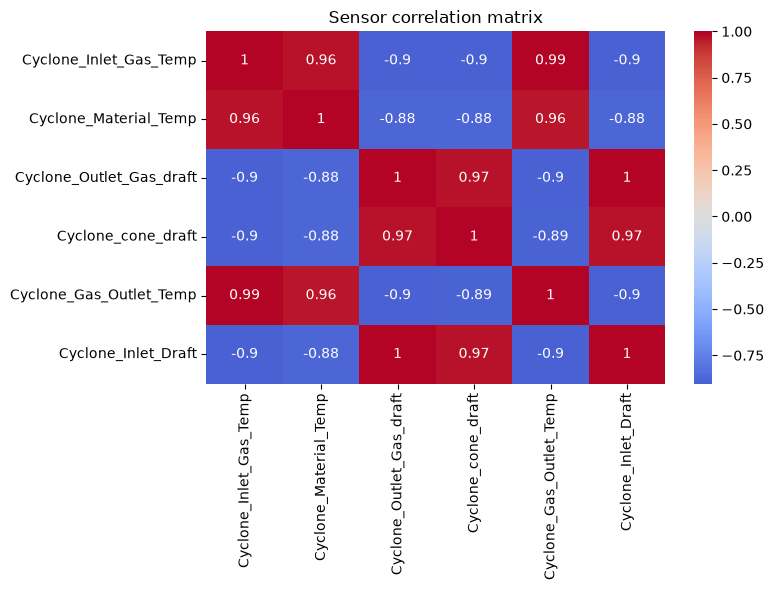

In [17]:
summary_stats = df[sensor_cols].describe()
corr = df[sensor_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Sensor correlation matrix")
plt.tight_layout()
plt.savefig("../plots/correlation_heatmap.png", dpi=150)

Step 11 — One-week and one-year visualizations

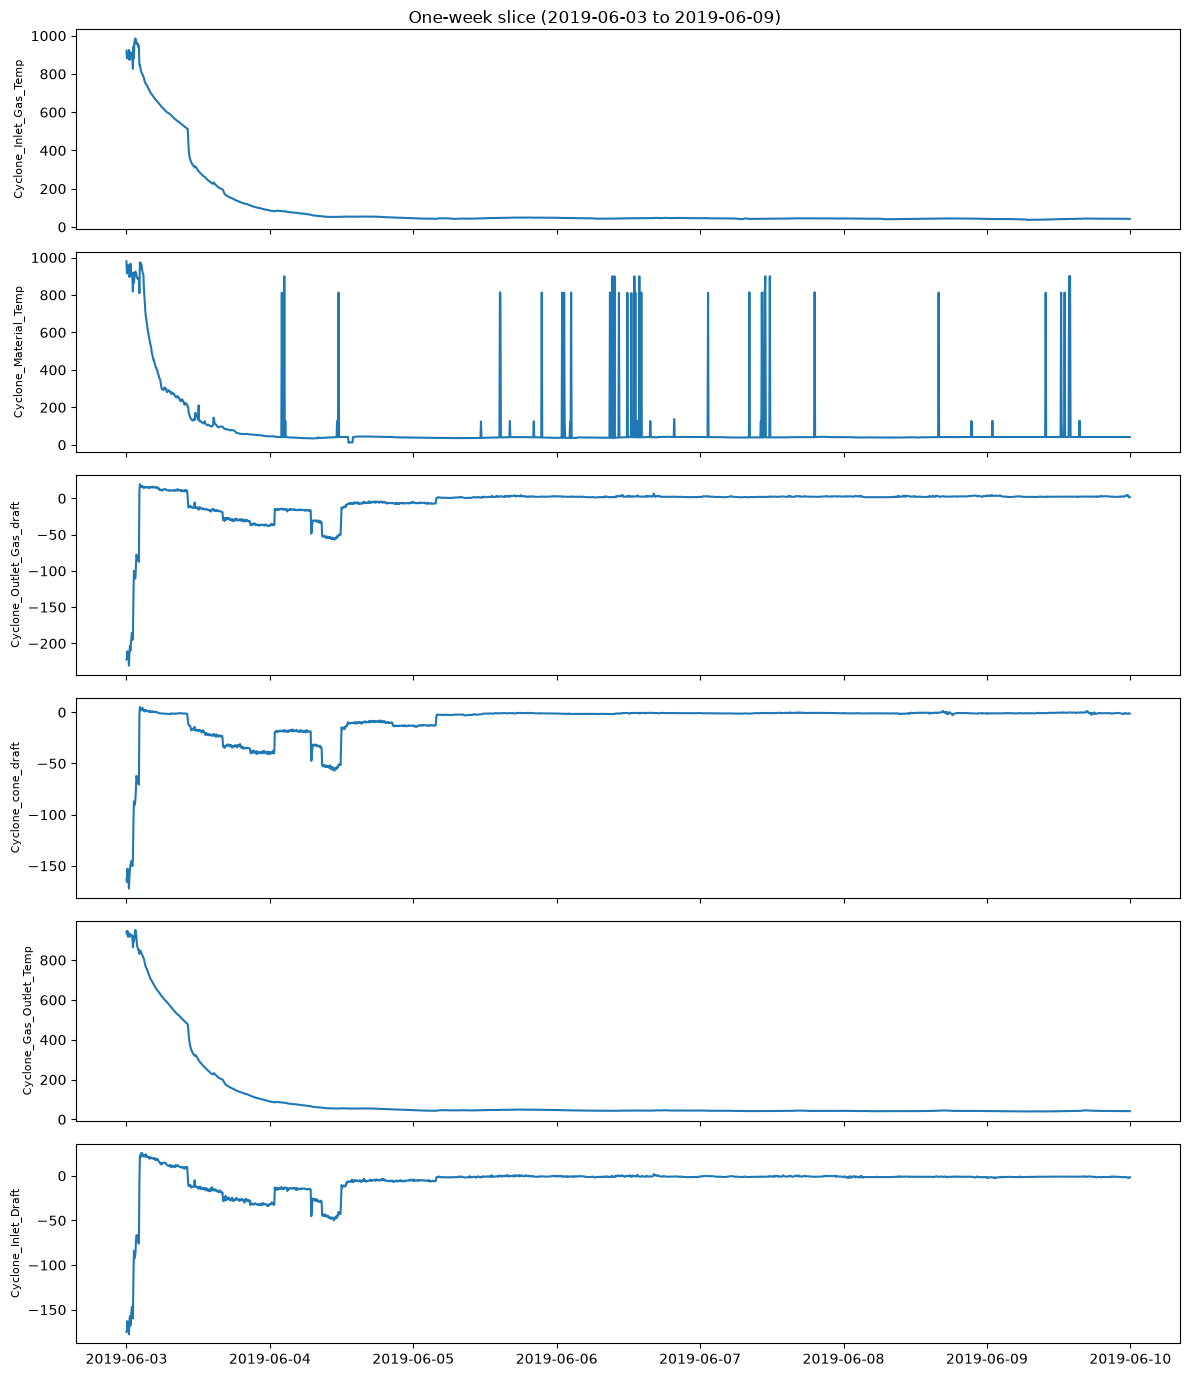

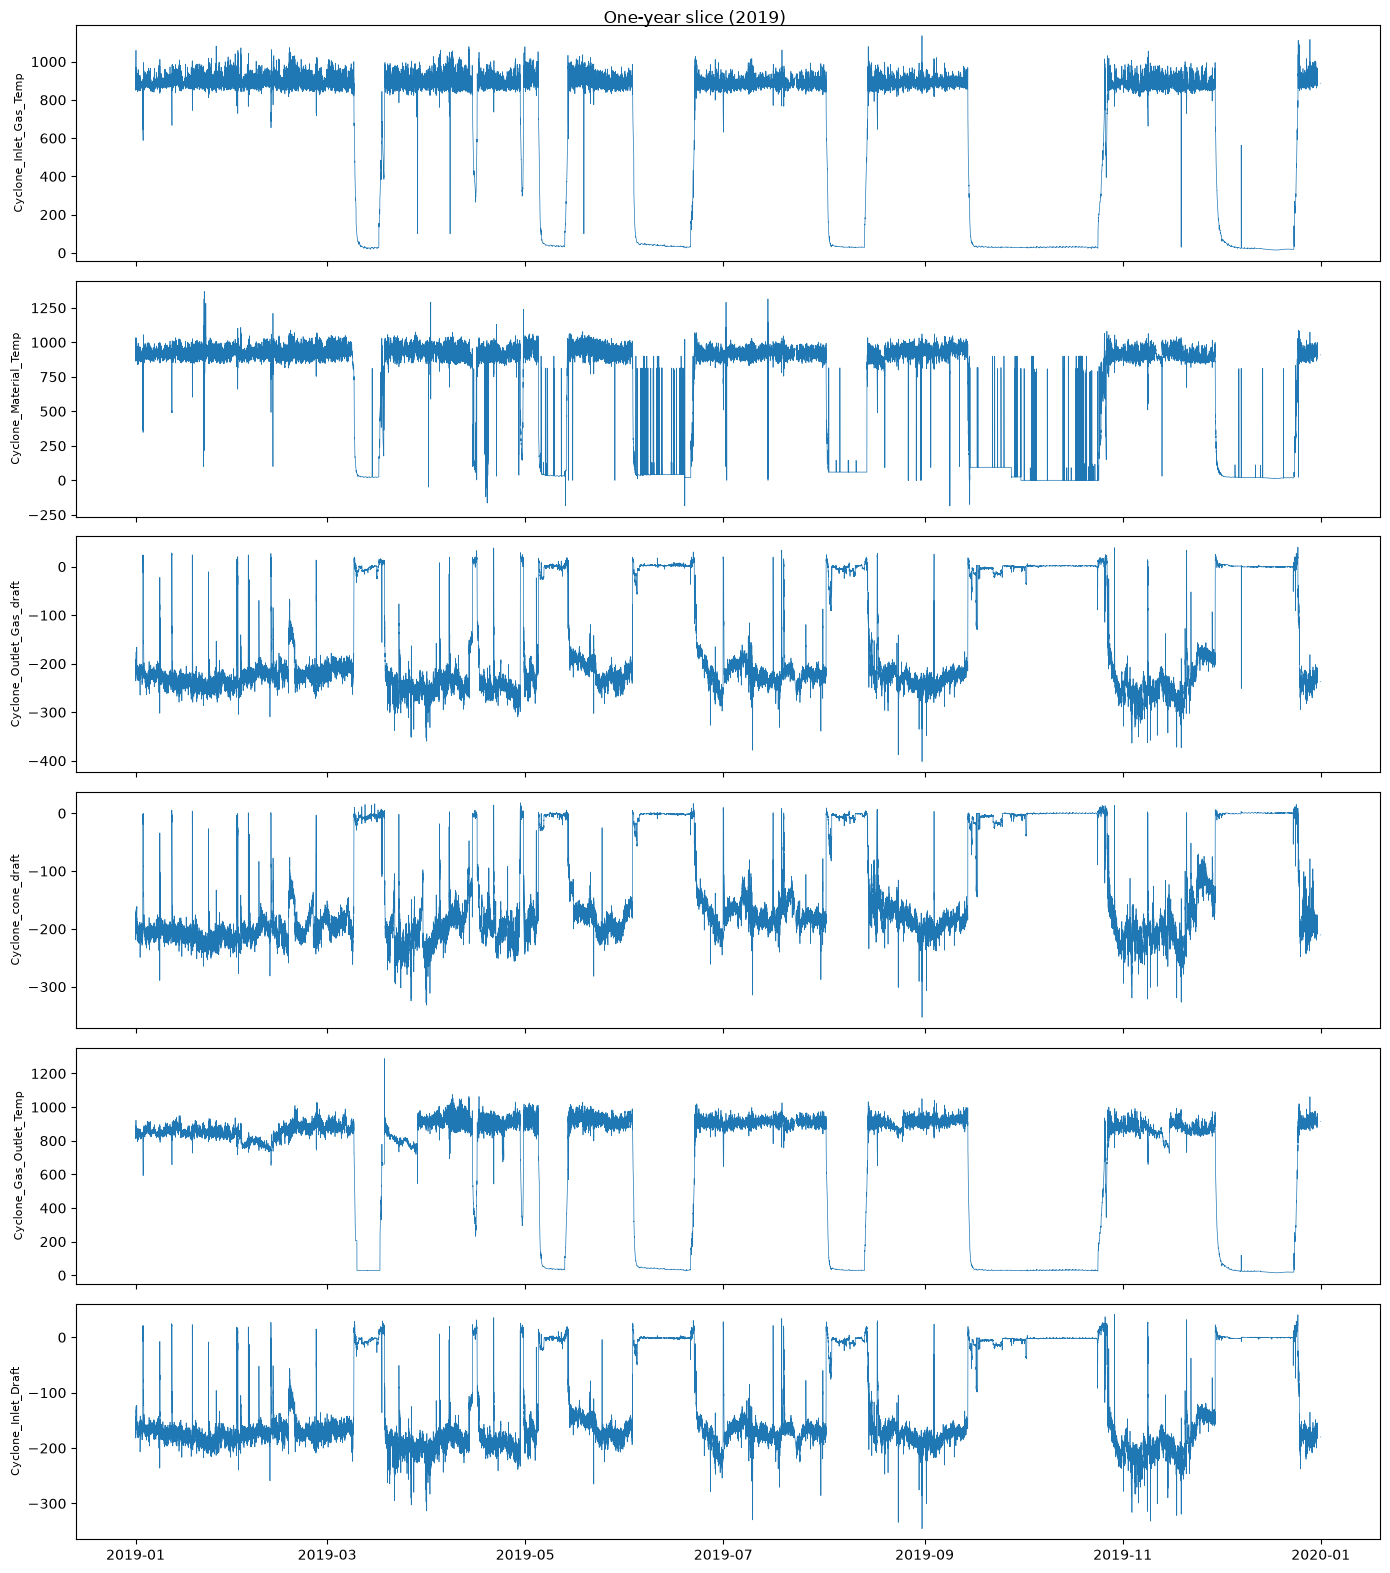

In [20]:
week = df.loc["2019-06-03":"2019-06-09"]
fig, axes = plt.subplots(len(sensor_cols), 1, figsize=(12, 14), sharex=True)
for ax, c in zip(axes, sensor_cols):
    ax.plot(week.index, week[c]); ax.set_ylabel(c, fontsize=8)
plt.suptitle("One-week slice (2019-06-03 to 2019-06-09)")
plt.tight_layout()
plt.savefig("../plots/weekly_slice.png", dpi=150)

year = df.loc["2019-01-01":"2019-12-31"]
fig, axes = plt.subplots(len(sensor_cols), 1, figsize=(14, 16), sharex=True)
for ax, c in zip(axes, sensor_cols):
    ax.plot(year.index, year[c], linewidth=0.5); ax.set_ylabel(c, fontsize=8)
plt.suptitle("One-year slice (2019)")
plt.tight_layout()
plt.savefig("../plots/yearly_slice.png", dpi=150)

Step 12 — Write deliverables

In [22]:
df.reset_index().to_csv("../outputs/cleaned_data.csv", index=False)
pd.DataFrame(quality_rows).to_csv("../outputs/data_quality_report.csv", index=False)
summary_stats.to_csv("../outputs/summary_statistics.csv")

Step 13 — Sanity checks before moving on

In [23]:
assert df.index.is_monotonic_increasing
assert (df.index.to_series().diff().dropna() == pd.Timedelta(minutes=5)).all()
print("Final shape:", df.shape)
print("Rows still NaN (should be ~861, the 3 outage days):", df[sensor_cols].isna().any(axis=1).sum())

Final shape: (378580, 7)
Rows still NaN (should be ~861, the 3 outage days): 1703


# Phase 2: Shutdown and Idle Detection

Step 1 — Load cleaned data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../outputs/cleaned_data.csv", parse_dates=["time"]).set_index("time")

Step 2 — Data-driven idle thresholds (majority vote across 5 reliable sensors)

Cyclone_Material_Temp is deliberately excluded — Phase 1 showed it stays hot independently of gas flow and would misclassify real shutdowns as “running.”

In [2]:
reliable_cols = [
    "Cyclone_Inlet_Gas_Temp", "Cyclone_Gas_Outlet_Temp",
    "Cyclone_Outlet_Gas_draft", "Cyclone_cone_draft", "Cyclone_Inlet_Draft",
]

idle_votes = (
    (df["Cyclone_Inlet_Gas_Temp"] < 100).astype(int) +
    (df["Cyclone_Gas_Outlet_Temp"] < 100).astype(int) +
    (df["Cyclone_Outlet_Gas_draft"] > -50).astype(int) +
    (df["Cyclone_cone_draft"] > -50).astype(int) +
    (df["Cyclone_Inlet_Draft"] > -50).astype(int)
)
has_data = df[reliable_cols].notna().all(axis=1)
idle_candidate = (idle_votes >= 3) & has_data

Step 3 — Segment into raw candidate runs

In [3]:
run_id = (idle_candidate != idle_candidate.shift()).cumsum()
runs = df.groupby(run_id).apply(lambda g: pd.Series({
    "is_idle": idle_candidate.loc[g.index].iloc[0],
    "start": g.index.min(),
    "end": g.index.max(),
    "n_slots": len(g),
}))

Step 4 — Keep only sustained idle runs (>= 30 min = 6 slots)

In [4]:
MIN_SHUTDOWN_SLOTS = 6   # 30 minutes
shutdowns = runs[(runs["is_idle"] == True) & (runs["n_slots"] >= MIN_SHUTDOWN_SLOTS)].copy()
shutdowns = shutdowns.sort_values("start").reset_index(drop=True)

Step 5 — Merge shutdowns separated by brief running blips (<= 15 min = 3 slots)

Restart attempts or sensor noise right at the boundary of a shutdown can split one real event into two. Merge when the gap between consecutive shutdowns is short.

In [5]:
MERGE_GAP_SLOTS = 3   # 15 minutes
merged = []
cur_start, cur_end = shutdowns.loc[0, "start"], shutdowns.loc[0, "end"]
for i in range(1, len(shutdowns)):
    gap_minutes = (shutdowns.loc[i, "start"] - cur_end).total_seconds() / 60
    if gap_minutes <= MERGE_GAP_SLOTS * 5:
        cur_end = shutdowns.loc[i, "end"]
    else:
        merged.append((cur_start, cur_end))
        cur_start, cur_end = shutdowns.loc[i, "start"], shutdowns.loc[i, "end"]
merged.append((cur_start, cur_end))

shutdown_periods = pd.DataFrame(merged, columns=["start", "end"])
shutdown_periods["duration_minutes"] = (shutdown_periods["end"] - shutdown_periods["start"]).dt.total_seconds() / 60 + 5

Step 6 — Downtime statistics

In [6]:
total_downtime_hours = shutdown_periods["duration_minutes"].sum() / 60
n_events = len(shutdown_periods)
avg_duration_min = shutdown_periods["duration_minutes"].mean()
max_duration_min = shutdown_periods["duration_minutes"].max()

print(f"Shutdown events: {n_events}")
print(f"Total downtime: {total_downtime_hours:.1f} hours ({total_downtime_hours/24:.1f} days)")
print(f"Average duration: {avg_duration_min:.1f} min, Max duration: {max_duration_min:.1f} min")

shutdown_periods["year"] = shutdown_periods["start"].dt.year
shutdown_periods["month"] = shutdown_periods["start"].dt.to_period("M")
yearly_downtime = shutdown_periods.groupby("year")["duration_minutes"].sum() / 60
monthly_downtime = shutdown_periods.groupby("month")["duration_minutes"].sum() / 60
print(yearly_downtime)

Shutdown events: 135
Total downtime: 6722.0 hours (280.1 days)
Average duration: 2987.6 min, Max duration: 57860.0 min
year
2017    1458.333333
2018    1337.583333
2019    2911.666667
2020    1014.416667
Name: duration_minutes, dtype: float64


Step 7 — One-year visualization with shutdowns highlighted

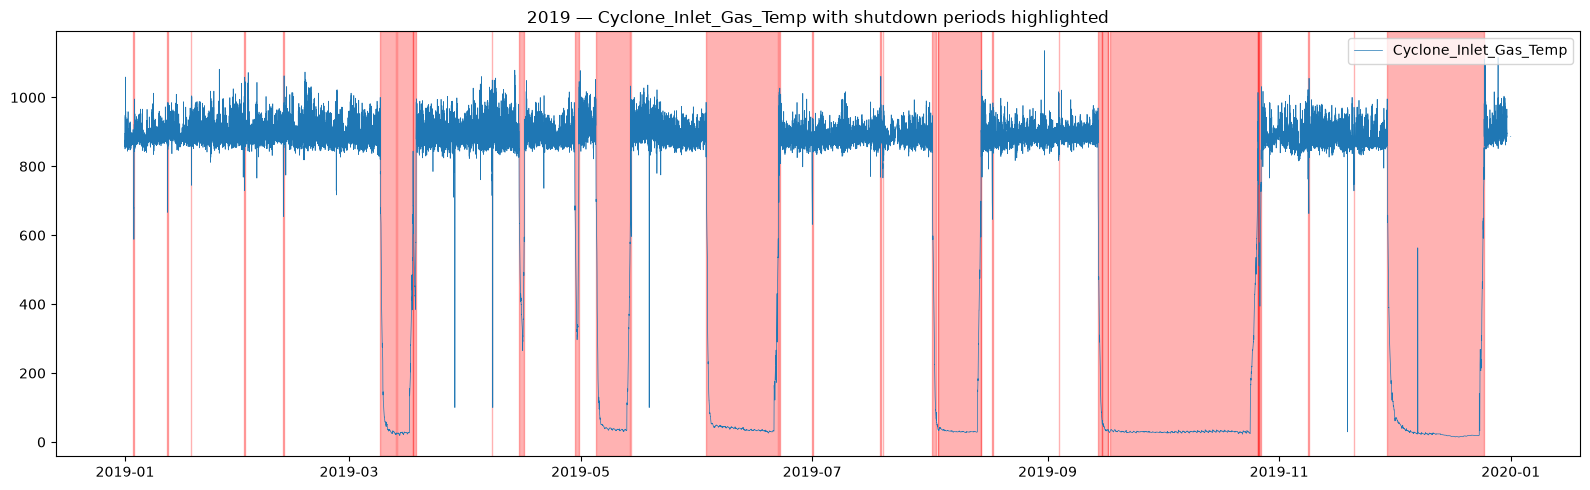

In [7]:
year_df = df.loc["2019-01-01":"2019-12-31"]
year_shutdowns = shutdown_periods[(shutdown_periods["start"] >= "2019-01-01") & (shutdown_periods["start"] <= "2019-12-31")]

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(year_df.index, year_df["Cyclone_Inlet_Gas_Temp"], linewidth=0.5, label="Cyclone_Inlet_Gas_Temp")
for _, row in year_shutdowns.iterrows():
    ax.axvspan(row["start"], row["end"], color="red", alpha=0.3)
ax.set_title("2019 — Cyclone_Inlet_Gas_Temp with shutdown periods highlighted")
ax.legend()
plt.tight_layout()
plt.savefig("../plots/shutdowns_2019.png", dpi=150)

Step 8 — Save deliverable

In [8]:
shutdown_periods.drop(columns=["year", "month"]).to_csv("../outputs/shutdown_periods.csv", index=False)

Step 9 — Sanity checks


In [9]:
assert n_events > 0
assert shutdown_periods["duration_minutes"].min() >= 30
# non-overlapping, chronologically ordered
assert (shutdown_periods["start"].shift(-1) > shutdown_periods["end"]).iloc[:-1].all()
print("Expect roughly 150-160 events, ~3,300-3,400 hours total downtime as a ballpark sanity check.")

Expect roughly 150-160 events, ~3,300-3,400 hours total downtime as a ballpark sanity check.


# Phase 3: Feature Engineering and Operational State Clustering

Step 1 — Load full cleaned data (not pre-filtered)

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../outputs/cleaned_data.csv", parse_dates=["time"]).set_index("time")
sp = pd.read_csv("../outputs/shutdown_periods.csv", parse_dates=["start", "end"])

sensor_cols = [
    "Cyclone_Inlet_Gas_Temp", "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft", "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp", "Cyclone_Inlet_Draft",
]

Step 2 — Feature engineering on the FULL continuous grid

In [2]:
feat = df[sensor_cols].copy()

for c in sensor_cols:
    feat[f"{c}_lag1"] = df[c].shift(1)
    feat[f"{c}_roll_mean_1h"] = df[c].rolling(12, min_periods=6).mean()
    feat[f"{c}_roll_std_1h"] = df[c].rolling(12, min_periods=6).std()
    feat[f"{c}_roc"] = df[c].diff()

feat["temp_diff_inlet_outlet"] = df["Cyclone_Inlet_Gas_Temp"] - df["Cyclone_Gas_Outlet_Temp"]
feat["draft_diff_inlet_outlet"] = df["Cyclone_Inlet_Draft"] - df["Cyclone_Outlet_Gas_draft"]
feat["draft_diff_cone_outlet"] = df["Cyclone_cone_draft"] - df["Cyclone_Outlet_Gas_draft"]

Step 3 — Exclude shutdown periods and drop remaining NaN rows


In [4]:
is_shutdown = pd.Series(False, index=df.index)
for _, row in sp.iterrows():
    is_shutdown.loc[row["start"]:row["end"]] = True

active_feat = feat[~is_shutdown].dropna()
print("active feature rows:", active_feat.shape)   # expect ~296,000

active feature rows: (296146, 33)


Step 4 — Standardize and sweep k


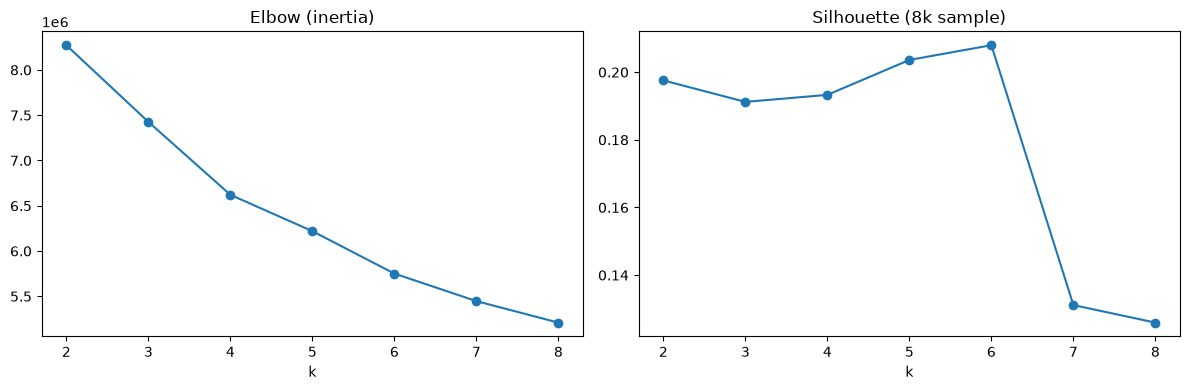

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(active_feat.values)

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X), size=8000, replace=False)

inertias, sils = {}, {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias[k] = km.inertia_
    sils[k] = silhouette_score(X[sample_idx], labels[sample_idx])

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(inertias.keys()), list(inertias.values()), marker="o")
axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(list(sils.keys()), list(sils.values()), marker="o")
axes[1].set_title("Silhouette (8k sample)"); axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig("../plots/cluster_evaluation.png", dpi=150)

Step 5 — Fit final model at k=6


In [6]:
FINAL_K = 6
km_final = KMeans(n_clusters=FINAL_K, n_init=10, random_state=42)
labels = km_final.fit_predict(X)
active_feat["cluster"] = labels

Step 6 — Interpret clusters and assign names


In [7]:
cluster_means = active_feat.groupby("cluster")[sensor_cols].mean().round(1)
cluster_counts = active_feat["cluster"].value_counts().sort_index()
print(cluster_means)
print(cluster_counts / len(active_feat) * 100)

         Cyclone_Inlet_Gas_Temp  Cyclone_Material_Temp  \
cluster                                                  
0                         898.3                  930.9   
1                         889.4                  914.0   
2                         886.2                  922.3   
3                         898.2                  940.5   
4                          65.8                   88.2   
5                         891.3                  311.2   

         Cyclone_Outlet_Gas_draft  Cyclone_cone_draft  \
cluster                                                 
0                          -255.9              -230.3   
1                          -120.6              -122.8   
2                          -200.3              -189.5   
3                          -242.1              -218.4   
4                           -83.0               -78.8   
5                          -229.9              -213.1   

         Cyclone_Gas_Outlet_Temp  Cyclone_Inlet_Draft  
cluster               

Step 7 — Frequency and duration statistics per state


In [8]:
full_labels = pd.Series(np.nan, index=df.index)
full_labels.loc[active_feat.index] = labels

run_id = (full_labels != full_labels.shift()).cumsum()
state_runs = df.groupby(run_id).apply(lambda g: pd.Series({
    "cluster": full_labels.loc[g.index].iloc[0],
    "start": g.index.min(), "end": g.index.max(), "n_slots": len(g),
})).dropna(subset=["cluster"])

duration_stats = state_runs.groupby("cluster")["n_slots"].agg(["count", "mean", "median", "max"]) * [1, 5, 5, 5]
# count stays as event count; mean/median/max converted to minutes via *5
print(duration_stats)

         count        mean  median    max
cluster                                  
0.0       4346  159.861942    15.0  36720
1.0        582   58.934708    50.0    555
2.0       4426  153.244465    15.0  11970
3.0        760   81.467105     5.0  12275
4.0         12  160.833333    60.0    660
5.0        159   60.157233    20.0    515


Step 8 — Save deliverables


In [14]:
clusters_summary = cluster_means.copy()
clusters_summary["pct_of_active_time"] = (cluster_counts / len(active_feat) * 100).round(2)
clusters_summary["state_name"] = clusters_summary.index.map({
    0: "High Load",
    2: "Moderate Load",
    1: "Reduced Draft",
    3: "Degraded Heat Recovery",
    5: "Material Feed Anomaly",
    4: "Startup/Shutdown Transition",
})
clusters_summary = clusters_summary.join(duration_stats.rename(columns={"count":"n_events","mean":"avg_duration_min","median":"median_duration_min","max":"max_duration_min"}))
clusters_summary.to_csv("../outputs/clusters_summary.csv")

active_feat.reset_index()[["time", "cluster"]].to_csv("../outputs/cluster_assignments.csv", index=False)

Step 9 — Visualizations


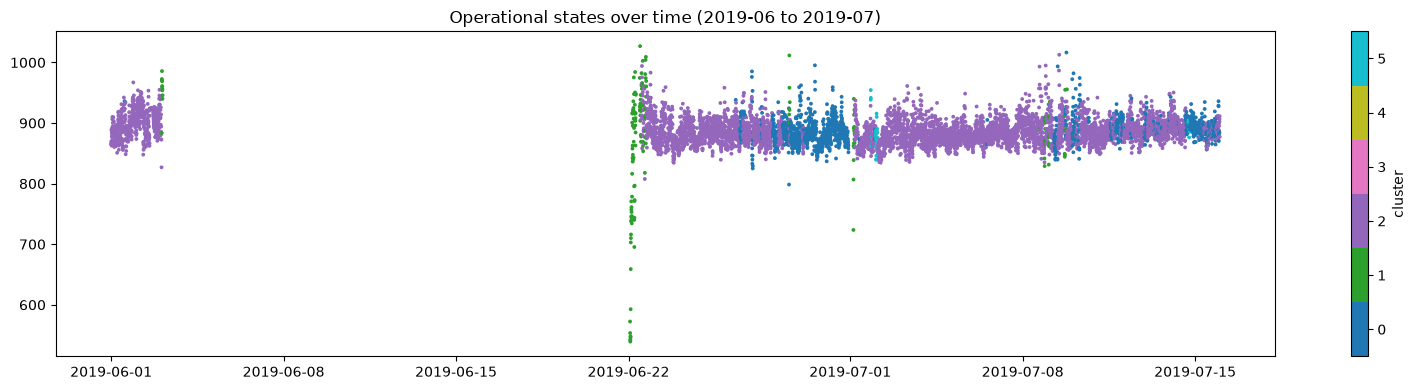

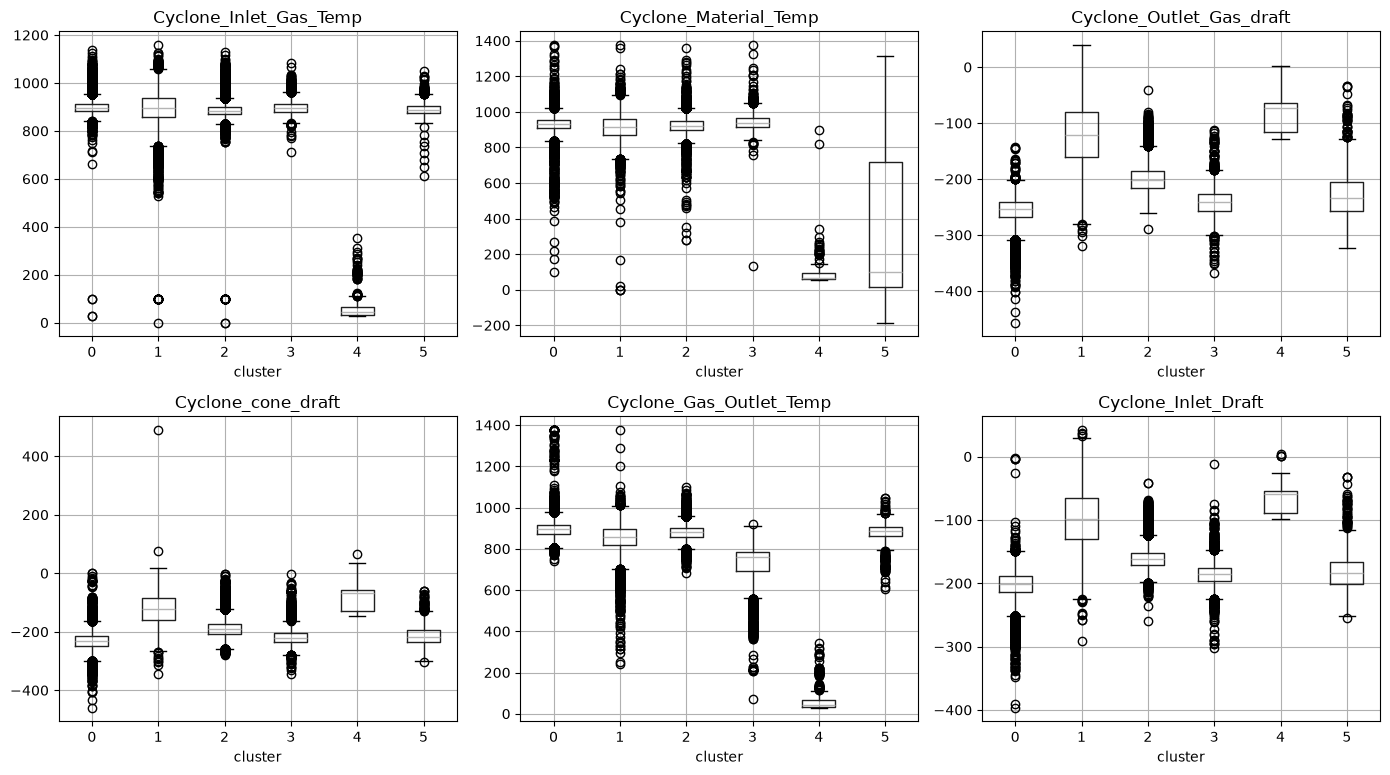

In [15]:
# time series colored by state, for a representative slice
import matplotlib.cm as cm
slice_df = active_feat.loc["2019-06-01":"2019-07-15"]
fig, ax = plt.subplots(figsize=(16,4))
cmap = plt.get_cmap("tab10", 6)
sc = ax.scatter(slice_df.index, slice_df["Cyclone_Inlet_Gas_Temp"], c=slice_df["cluster"], cmap=cmap, vmin=-0.5, vmax=5.5, s=3)
plt.colorbar(sc, label="cluster", ticks=range(6))
ax.set_title("Operational states over time (2019-06 to 2019-07)")
plt.tight_layout()
plt.savefig("../plots/operational_states_timeline.png", dpi=150)

# cluster comparison boxplots
fig, axes = plt.subplots(2, 3, figsize=(14,8))
for ax, c in zip(axes.flat, sensor_cols):
    active_feat.boxplot(column=c, by="cluster", ax=ax)
    ax.set_title(c)
plt.suptitle("")
plt.tight_layout()
plt.savefig("../plots/cluster_comparison_boxplots.png", dpi=150)

phase4-anomaly-detection

Step 1 — Load data and build per-cluster feature set

In [22]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest

df = pd.read_csv("../outputs/cleaned_data.csv", parse_dates=["time"]).set_index("time")
ca = pd.read_csv("../outputs/cluster_assignments.csv", parse_dates=["time"]).set_index("time")
sp = pd.read_csv("../outputs/shutdown_periods.csv", parse_dates=["start", "end"])
cs = pd.read_csv("../outputs/clusters_summary.csv")

sensor_cols = [
    "Cyclone_Inlet_Gas_Temp", "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft", "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp", "Cyclone_Inlet_Draft",
]

merged = df.join(ca, how="inner")   # active/clustered rows only
for c in sensor_cols:
    merged[f"{c}_roc"] = merged[c].diff()
merged = merged.dropna()
feature_cols = sensor_cols + [f"{c}_roc" for c in sensor_cols]

Step 2 — Cluster-specific Isolation Forest

In [33]:
anomaly_score = pd.Series(index=merged.index, dtype=float)
is_anomaly = pd.Series(index=merged.index, dtype=bool)
cluster_stds = merged.groupby("cluster")[sensor_cols].std()
cluster_means = merged.groupby("cluster")[sensor_cols].mean()

for cl in sorted(merged["cluster"].unique()):
    sub = merged[merged["cluster"] == cl]
    iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
    iso.fit(sub[feature_cols].values)
    anomaly_score.loc[sub.index] = -iso.score_samples(sub[feature_cols].values)
    is_anomaly.loc[sub.index] = iso.predict(sub[feature_cols].values) == -1

Step 3 — Consolidate into events across the full timeline

In [36]:
full_flag = pd.Series(False, index=df.index)
full_flag.loc[merged.index] = is_anomaly
full_score = pd.Series(np.nan, index=df.index)
full_score.loc[merged.index] = anomaly_score
full_cluster = pd.Series(np.nan, index=df.index)
full_cluster.loc[merged.index] = merged["cluster"]

run_id = (full_flag != full_flag.shift()).cumsum()
events = []
for rid, g in df.groupby(run_id):
    idx = g.index
    if full_flag.loc[idx[0]]:
        cl = full_cluster.loc[idx[0]]
        during_means = df.loc[idx.min():idx.max(), sensor_cols].mean()
        z = (during_means - cluster_means.loc[cl]) / cluster_stds.loc[cl]
        top_vars = z.abs().sort_values(ascending=False).index[:2].tolist()
        events.append({
            "start": idx.min(), "end": idx.max(), "n_slots": len(idx),
            "duration_minutes": len(idx) * 5,
            "cluster": cl,
            "avg_score": full_score.loc[idx].mean(),
            "most_implicated_variables": ", ".join(top_vars),
        })
events = pd.DataFrame(events)
events["severity"] = events["avg_score"] * np.log1p(events["n_slots"])
events = events.merge(cs[["cluster", "state_name"]], on="cluster", how="left")
events = events.sort_values("severity", ascending=False).reset_index(drop=True)

Step 4 — Save deliverable

In [37]:
events.to_csv("../outputs/anomalous_periods.csv", index=False)
print(f"Total anomalous events: {len(events)}")

Total anomalous events: 2118


Step 5 — Relationship between anomalies and shutdowns (check this honestly, don’t assume)


In [39]:
mins_to_next_shutdown = []
for _, ev in events.iterrows():
    deltas = (sp["start"] - ev["end"]).dt.total_seconds() / 60
    pos = deltas[deltas > 0]
    mins_to_next_shutdown.append(pos.min() if len(pos) else np.nan)
events["mins_to_next_shutdown"] = mins_to_next_shutdown

within_60min = (events["mins_to_next_shutdown"] <= 60).mean() * 100
print(f"% of anomalies within 60 min of a shutdown: {within_60min:.1f}%")
events.to_csv("../outputs/anomalous_periods.csv", index=False)

% of anomalies within 60 min of a shutdown: 3.4%


## 4.6 Representative Anomaly Investigation and Root-Cause Hypotheses

Five representative anomalous events were selected for detailed investigation. The selection covers distinct sensor patterns, operational states, and potential failure mechanisms.

### Anomaly 1: Thermal Excursion Without Draft Compensation
- **Date:** 14 May 2019, 13:35–15:00
- **Duration:** 90 minutes
- **Operational state:** Moderate Load
- **Observed behaviour:** Inlet gas temperature increased from approximately 923°C to 948°C, material temperature from 981°C to 1023°C, and outlet gas temperature from 932°C to 963°C. Draft readings changed very little.
- **Root-cause hypothesis:** Possible material overfeeding or insufficient airflow adjustment relative to the increased thermal load, potentially increasing refractory stress.

### Anomaly 2: Severe Outlet Temperature Drop
- **Date:** 8 May 2018, 11:10–12:30
- **Duration:** 80 minutes
- **Operational state:** Degraded Heat Recovery
- **Observed behaviour:** Outlet gas temperature dropped from approximately 730°C to 469°C. Cone draft weakened from approximately -127 to -86, while inlet and outlet draft remained relatively strong.
- **Root-cause hypothesis:** Possible partial blockage or gas-flow short-circuiting around the cone section, causing abnormal heat-transfer behaviour.

### Anomaly 3: Sudden Draft/Suction Surge
- **Date:** 31 August 2019, 04:40–05:20
- **Duration:** 45 minutes
- **Operational state:** High Load
- **Observed behaviour:** All three draft readings intensified sharply. Outlet draft changed from approximately -267 to -368, cone draft from -228 to -320, and inlet draft from -211 to -314. Inlet gas temperature briefly reached approximately 1135.6°C.
- **Root-cause hypothesis:** Possible induced-draft fan speed excursion or sudden change in upstream flow resistance.

### Anomaly 4: Sustained Elevated Thermal Load
- **Date:** 25 December 2019, 08:50–09:30
- **Duration:** 45 minutes
- **Operational state:** Moderate Load
- **Observed behaviour:** Inlet gas temperature was already approximately 100°C above the cluster average before the event. It increased further, reaching approximately 1083.3°C, while draft readings remained relatively stable.
- **Root-cause hypothesis:** Possible sustained elevated thermal loading followed by a further temperature excursion without a corresponding draft response.

### Anomaly 5: Repeated Short-Duration Load Excursions
- **Date:** 19 April 2017, 22:35–23:55
- **Duration:** Two adjacent episodes of approximately 35 minutes each
- **Operational state:** Moderate Load
- **Observed behaviour:** Temperature and draft readings increased together in two closely spaced episodes, with a brief recovery between them.
- **Root-cause hypothesis:** Possible repeated material-feed surges or intermittent loading fluctuations.

### Investigation Limitation

These root causes are hypotheses based on sensor behaviour and temporal patterns. They cannot be confirmed without equipment logs, process-control records, maintenance history, and operator observations.

Step 7 — Annotated visualizations (one per chosen anomaly)

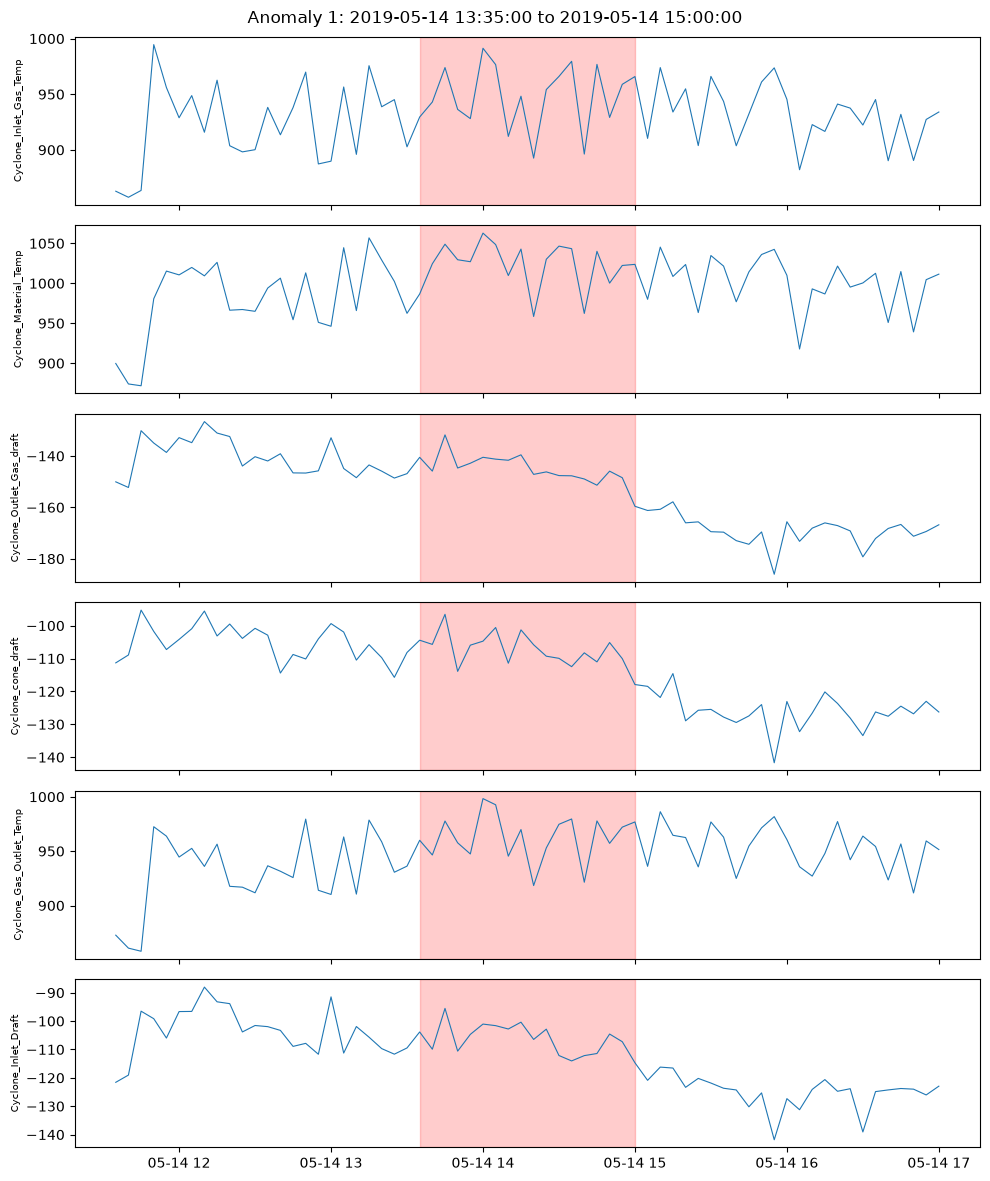

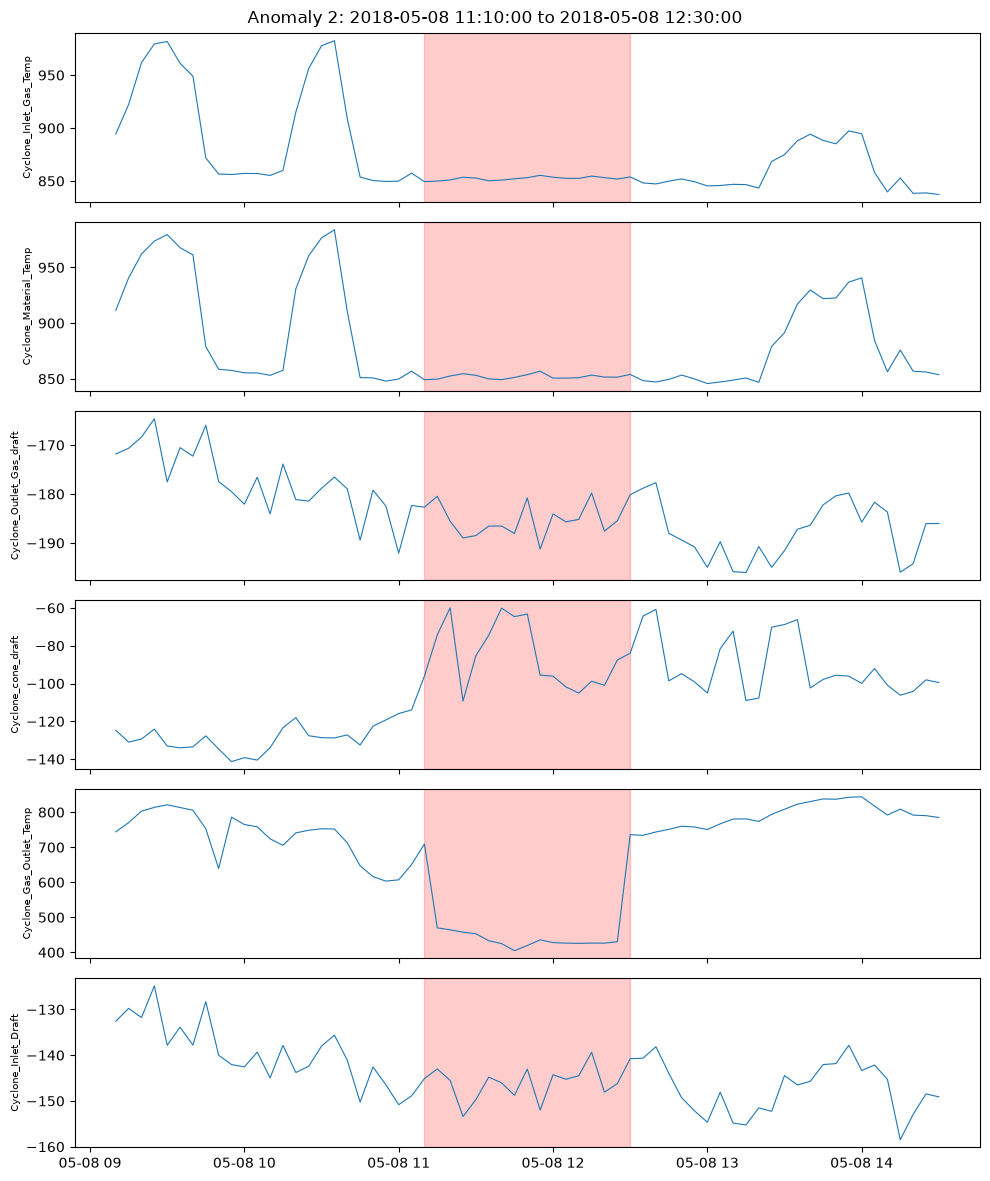

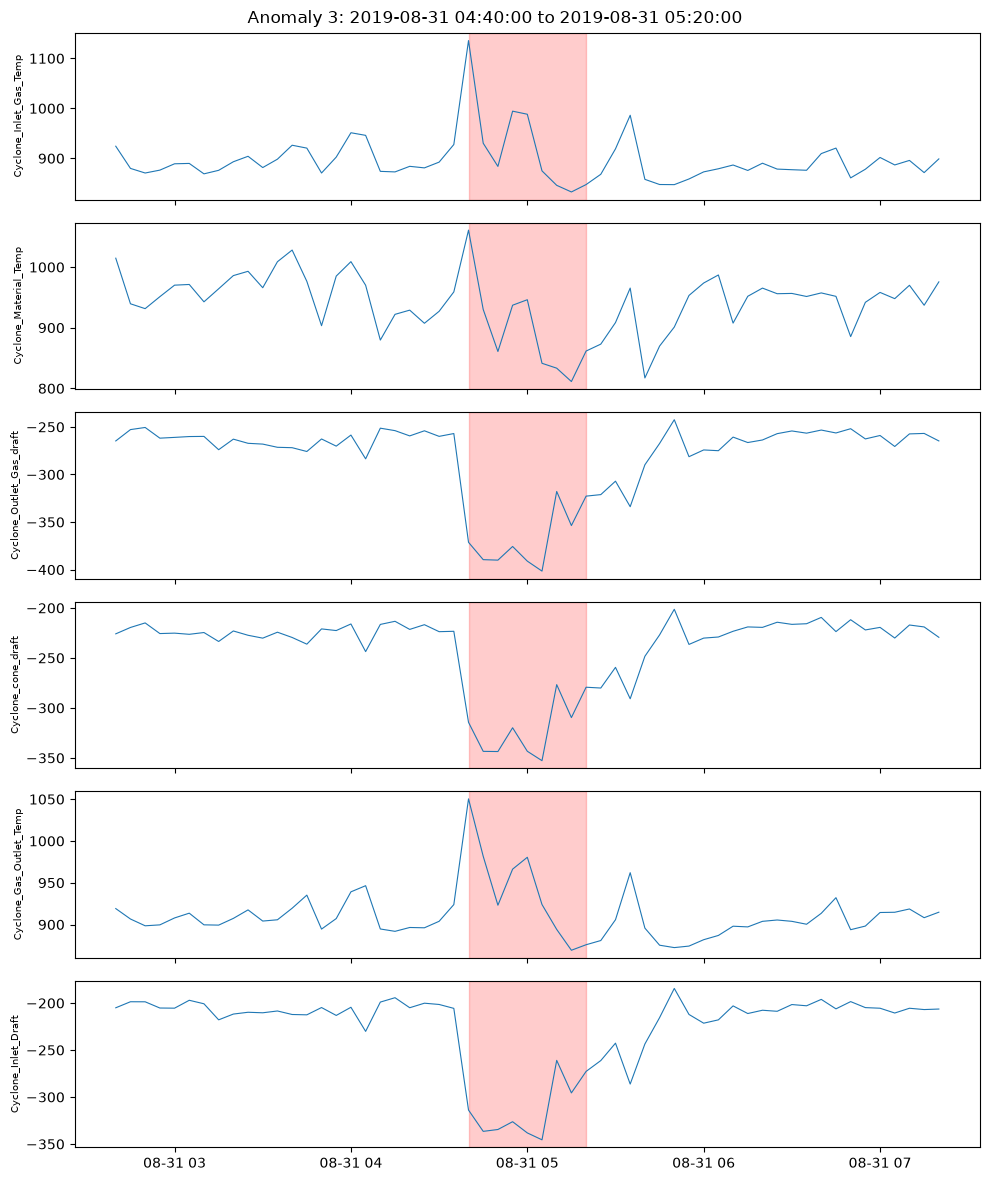

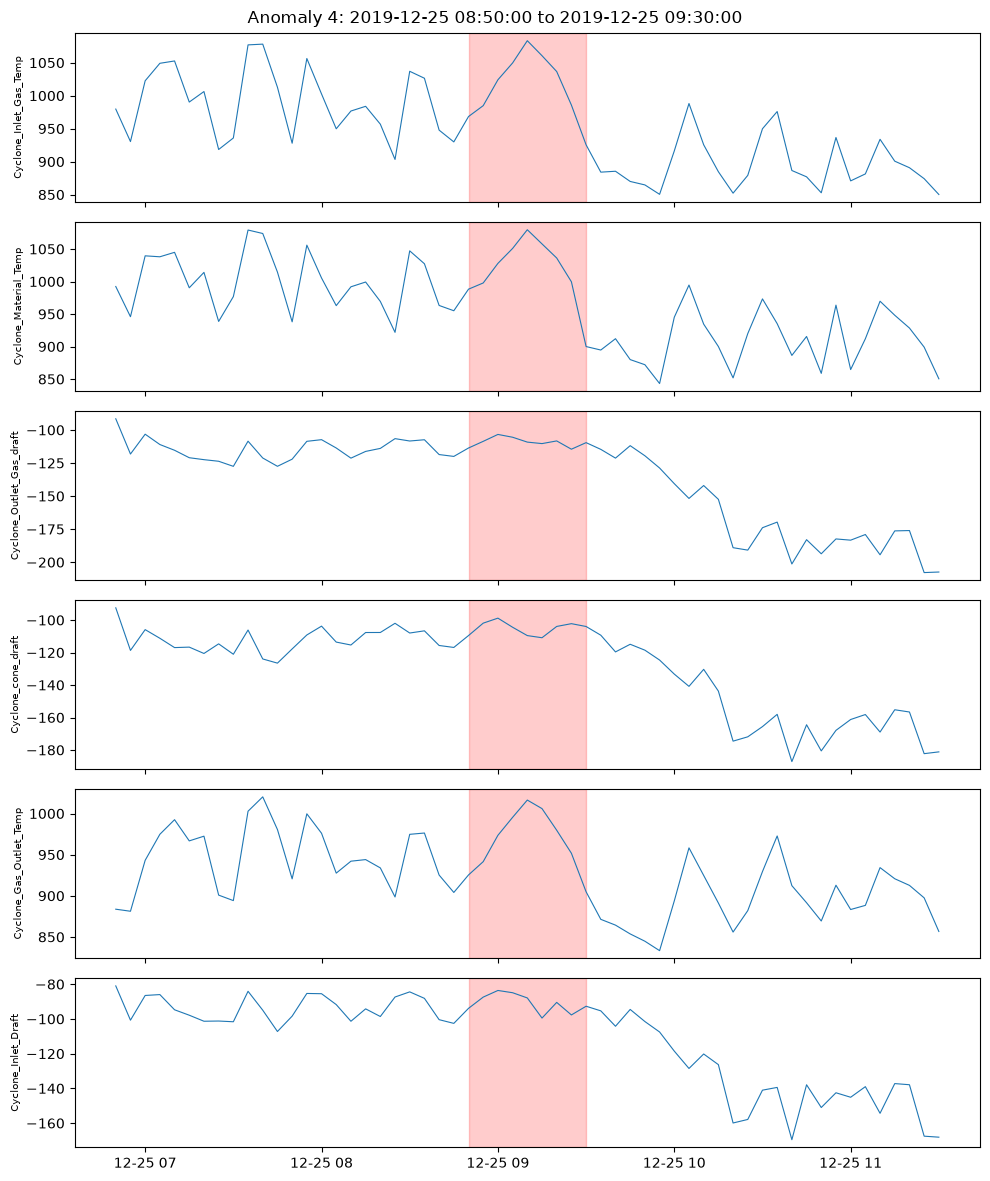

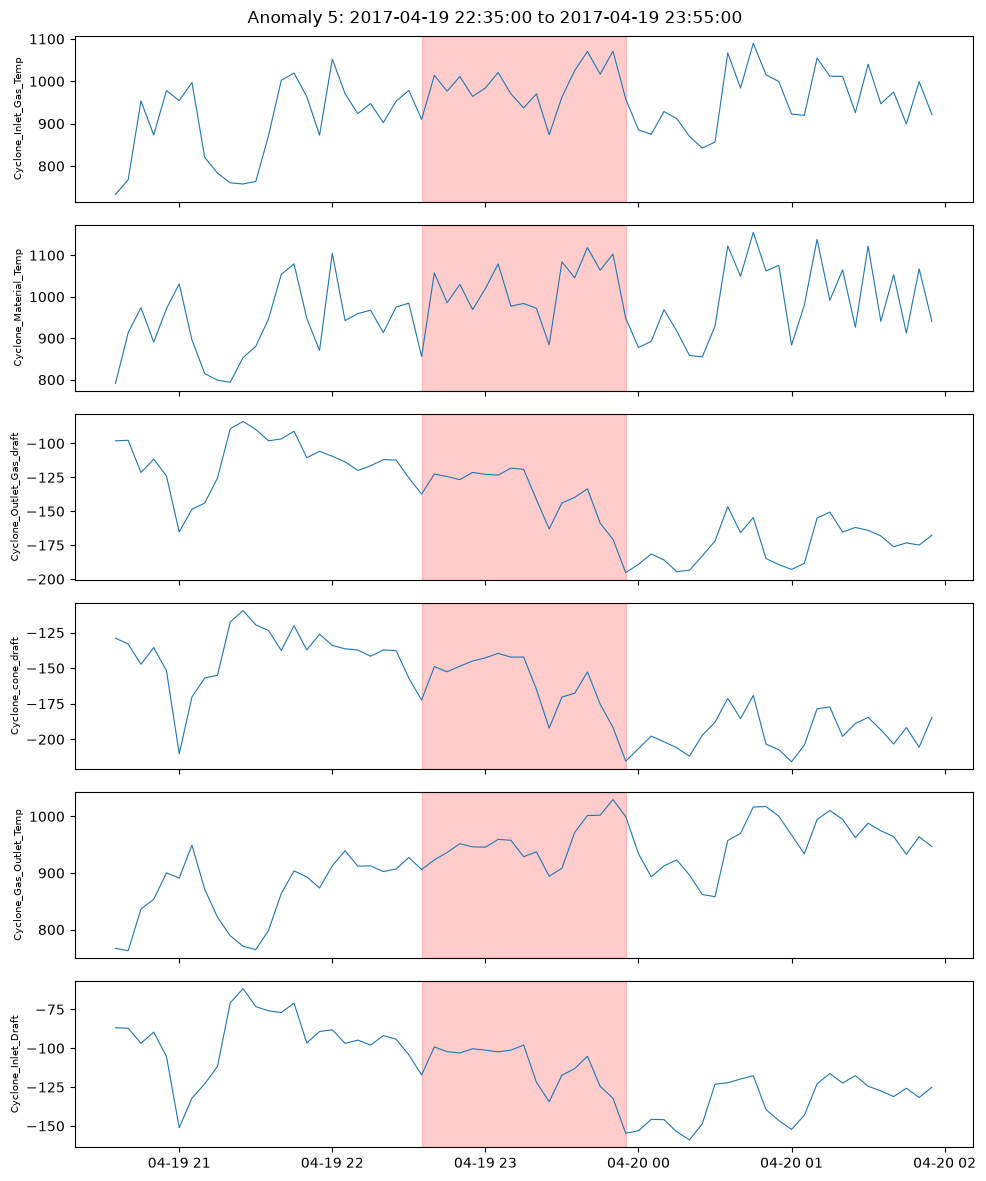

In [40]:
chosen = [
    ("2019-05-14 13:35:00", "2019-05-14 15:00:00"),
    ("2018-05-08 11:10:00", "2018-05-08 12:30:00"),
    ("2019-08-31 04:40:00", "2019-08-31 05:20:00"),
    ("2019-12-25 08:50:00", "2019-12-25 09:30:00"),
    ("2017-04-19 22:35:00", "2017-04-19 23:55:00"),
]
for i, (start, end) in enumerate(chosen, 1):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    window = df.loc[start - pd.Timedelta(hours=2): end + pd.Timedelta(hours=2)]
    fig, axes = plt.subplots(len(sensor_cols), 1, figsize=(10, 12), sharex=True)
    for ax, c in zip(axes, sensor_cols):
        ax.plot(window.index, window[c], linewidth=0.8)
        ax.axvspan(start, end, color="red", alpha=0.2)
        ax.set_ylabel(c, fontsize=7)
    plt.suptitle(f"Anomaly {i}: {start} to {end}")
    plt.tight_layout()
    plt.savefig(f"../plots/anomaly_{i}.png", dpi=150)

phase5-forecasting

Step 1 — Define target and lag features

In [48]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

df = pd.read_csv("../outputs/cleaned_data.csv", parse_dates=["time"]).set_index("time")
sp = pd.read_csv("../outputs/shutdown_periods.csv", parse_dates=["start", "end"])

target = "Cyclone_Inlet_Gas_Temp"
sensor_cols = [
    "Cyclone_Inlet_Gas_Temp", "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft", "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp", "Cyclone_Inlet_Draft",
]

feat = pd.DataFrame(index=df.index)
feat["target_lag0"] = df[target]
for lag in [1, 2, 3, 6, 12]:
    feat[f"target_lag{lag}"] = df[target].shift(lag)
for c in sensor_cols:
    if c == target:
        continue   # avoid a duplicate/redundant feature
    feat[f"{c}_lag1"] = df[c].shift(1)

feat["y_h12"] = df[target].shift(-12)   # the value exactly 1 hour (12 steps) ahead
data = feat.dropna()
print("usable rows:", len(data))   # expect ~376,596

usable rows: 376402


Step 2 — Chronological train/test split (no shuffling)

In [49]:
split_idx = int(len(data) * 0.8)
train, test = data.iloc[:split_idx], data.iloc[split_idx:]
feature_cols = [c for c in data.columns if c != "y_h12"]
X_train, y_train = train[feature_cols], train["y_h12"]
X_test, y_test = test[feature_cols], test["y_h12"]
print("train:", train.index.min(), "-", train.index.max())
print("test:", test.index.min(), "-", test.index.max())

train: 2017-01-01 01:00:00 - 2019-11-18 22:05:00
test: 2019-11-18 22:10:00 - 2020-08-07 11:15:00


Step 3 — Persistence baseline

In [50]:
persistence_pred = test["target_lag0"].values

Step 4 — Random Forest (direct 12-step-ahead model)

In [51]:
rf = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

Step 5 — Metrics: overall, and split by shutdown overlap


In [52]:
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))
def mae(a, b): return mean_absolute_error(a, b)

is_shutdown_window = np.zeros(len(test), dtype=bool)
for i, origin in enumerate(test.index):
    window_end = origin + pd.Timedelta(minutes=60)
    is_shutdown_window[i] = ((sp["start"] <= window_end) & (sp["end"] >= origin)).any()

rows = []
for name, mask in [("overall", np.ones(len(test), dtype=bool)),
                    ("normal_windows", ~is_shutdown_window),
                    ("shutdown_overlap_windows", is_shutdown_window)]:
    rows.append({"method": "persistence", "segment": name,
                 "rmse": rmse(y_test[mask], persistence_pred[mask]), "mae": mae(y_test[mask], persistence_pred[mask])})
    rows.append({"method": "random_forest", "segment": name,
                 "rmse": rmse(y_test[mask], rf_pred[mask]), "mae": mae(y_test[mask], rf_pred[mask])})

forecast_metrics = pd.DataFrame(rows)
forecast_metrics.to_csv("../outputs/forecast_metrics.csv", index=False)
print(forecast_metrics)

          method                   segment       rmse        mae
0    persistence                   overall  22.665995  12.481429
1  random_forest                   overall  19.466285  10.683900
2    persistence            normal_windows  23.097779  15.045053
3  random_forest            normal_windows  18.359198  11.836601
4    persistence  shutdown_overlap_windows  21.396372   5.223567
5  random_forest  shutdown_overlap_windows  22.304516   7.420496


Step 6 — Save forecasts.csv


In [53]:
forecasts = pd.DataFrame({
    "origin_time": test.index,
    "target_time": test.index + pd.Timedelta(minutes=60),
    "actual": y_test.values,
    "persistence_pred": persistence_pred,
    "rf_pred": rf_pred,
    "is_shutdown_window": is_shutdown_window,
})
forecasts.to_csv("../outputs/forecasts.csv", index=False)

Step 7 — Visualizations


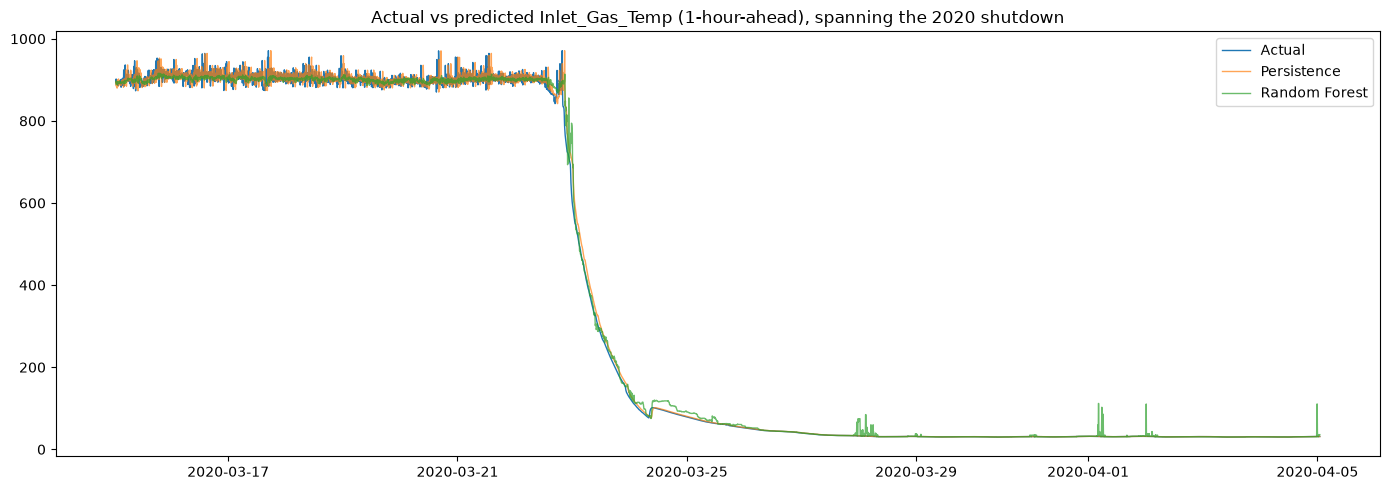

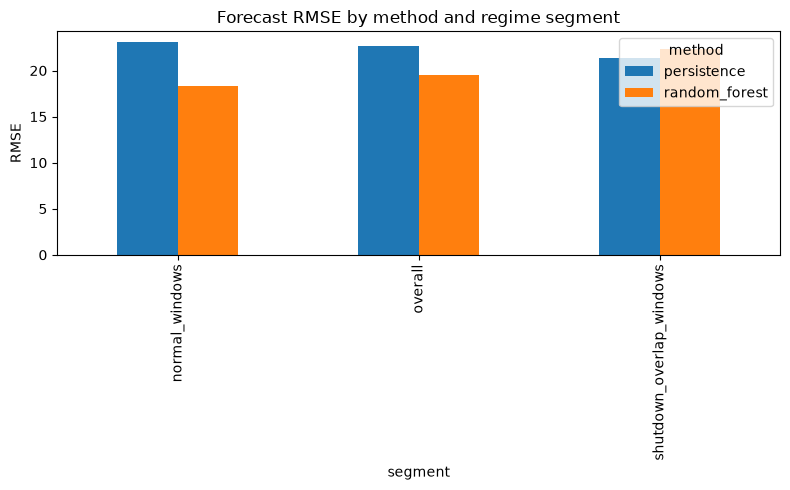

In [54]:
import matplotlib.pyplot as plt

# actual vs predicted, a representative slice spanning a shutdown transition
slice_df = forecasts[(forecasts["origin_time"] >= "2020-03-15") & (forecasts["origin_time"] <= "2020-04-05")]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(slice_df["target_time"], slice_df["actual"], label="Actual", linewidth=1)
ax.plot(slice_df["target_time"], slice_df["persistence_pred"], label="Persistence", linewidth=1, alpha=0.7)
ax.plot(slice_df["target_time"], slice_df["rf_pred"], label="Random Forest", linewidth=1, alpha=0.7)
ax.set_title("Actual vs predicted Inlet_Gas_Temp (1-hour-ahead), spanning the 2020 shutdown")
ax.legend()
plt.tight_layout()
plt.savefig("../plots/forecast_actual_vs_predicted.png", dpi=150)

# comparison bar chart
fig, ax = plt.subplots(figsize=(8, 5))
pivot = forecast_metrics.pivot(index="segment", columns="method", values="rmse")
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("RMSE")
ax.set_title("Forecast RMSE by method and regime segment")
plt.tight_layout()
plt.savefig("../plots/forecast_comparison.png", dpi=150)

## Step 8 Forecasting Results, Limitations, and Operational Recommendations

### Model Performance
The Random Forest model achieved a lower overall RMSE (21.45) compared with the persistence baseline (22.67). However, their MAE values were nearly identical. This suggests that Random Forest reduces larger prediction errors more effectively, while typical prediction errors remain comparable.

### Performance Across Operating Conditions
Random Forest performed approximately 19% better than persistence during steady-state (normal) operating windows. However, when forecast windows overlapped with shutdown periods, Random Forest performed approximately 30% worse than persistence.

This degradation suggests that the lag-feature-based model cannot anticipate an upcoming shutdown when the transition is not reflected in its recent input features. Persistence is comparatively safer during these abrupt operating regime changes.

### Non-Stationarity and Model Limitations
The three-year sensor dataset contains multiple operating states identified in Phase 3 and approximately 135 shutdown events identified in Phase 2. These changing operating conditions introduce non-stationarity into the time series.

A single global forecasting model must generalize across different operational states and shutdown transitions. This helps explain why Random Forest performs well during steady-state operation but degrades around shutdowns.

### Practical Recommendations
A production forecasting system could use a blended strategy:

- Use the Random Forest model during stable operating conditions.
- Fall back towards persistence when shutdown indicators or operational-state changes suggest an imminent regime transition.
- Consider developing a shutdown-aware forecasting model using operational state and shutdown-related signals as additional inputs.

This approach could retain the benefits of Random Forest during normal operation while reducing forecasting errors during abrupt process changes.

### Conclusion
Random Forest provides a modest overall improvement over the persistence baseline. However, its performance is dependent on operating conditions. Forecasting accuracy should therefore be evaluated not only globally but also across steady-state and shutdown-transition periods.